# Test di Ipotesi


### Disegno degli Esperimenti


L'idea del **[disegno degli esperimenti](https://en.wikipedia.org/wiki/Design_of_experiments)** ha le sue origini nella statistica tradizionale e trova applicazioni in molte aree di ricerca. L'idea è quella di **progettare opportunamente un esperimento per confermare o rifiutare un'ipotesi**.

Gli analisti e i data scientist si trovano spesso nella necessità di condurre esperimenti riguardo interfacce utente, marketing di prodotto, pricing e così via. Qualcosa da tenere a mente è che i test statistici dovrebbero sempre essere usati per confermare o rifiutare un'ipotesi, non per trovare conferma nelle proprie idee o sensazioni; come disse saggiamente il poeta scozzese Andrew Lang:

> Usa la statistica come un ubriaco usa i lampioni... per appoggiarsi piuttosto che per illuminarsi.

Questo è approssimativamente come funziona il processo:

1. si formula un'ipotesi, come "il farmaco A è migliore del farmaco standard esistente" o, in un contesto business, "questa nuova landing page genera più conversioni di quella esistente";
2. un esperimento (come un **test A/B**) è progettato specificamente per testare l'ipotesi;
3. si iniziano a raccogliere i dati rilevanti e ad analizzarli;
4. una conclusione viene dedotta sulla base dei risultati.

<img src="img/inference-pipeline.png" width="900">

Il termine **[inferenza](https://en.wikipedia.org/wiki/Statistical_inference)** riflette il fatto che vogliamo generalizzare i risultati dell'esperimento, che coinvolgono un insieme limitato di dati (come un sottoinsieme casuale di clienti), a una popolazione più ampia (tutti i clienti).

Un esperimento ben condotto dovrebbe essere ben pianificato e documentato, la metrica obiettivo dovrebbe essere scelta con cura e nel caso di un **[test AB](https://en.wikipedia.org/wiki/A/B_testing)**, particolare attenzione dovrebbe essere posta nella randomizzazione dei gruppi test e controllo, oltre al raggiungimento di una dimensione campionaria sufficientemente grande.


### Test di Ipotesi


La definizione su Wikipedia dice che:

> Un **[test di ipotesi statistica](https://en.wikipedia.org/wiki/Statistical_hypothesis_testing)** è un metodo di inferenza statistica utilizzato per decidere se i dati a disposizione **supportano sufficientemente una particolare ipotesi**. Il test di ipotesi ci permette di fare **affermazioni probabilistiche sui parametri della popolazione**.

Dovrebbe essere chiaro dal capitolo precedente che dovremmo testare qualcosa solo dopo aver formulato debitamente un'ipotesi e progettato il processo che definisce l'esperimento, affinché le conclusioni del test possano essere considerate valide e affidabili.

All'ultimo passo del nostro processo di disegno dell'esperimento, dopo aver raccolto i dati, è il momento di **verificare se la nostra ipotesi è validata dai dati** oppure no. Risulta che esistono **test diversi** che possono essere condotti a seconda del tipo di fenomeno che stiamo misurando; il seguente diagramma di flusso può aiutarci a distinguere tutti i vari casi:

<img src="img/hyp-test-diagram.png" width="800">

Nella maggior parte dei casi aziendali avrete abbastanza dati e dovrete usare un z-test o un t-test.


#### z-test

Uno **[z-test](https://en.wikipedia.org/wiki/Z-test)** è un test statistico per il quale la distribuzione della statistica test sotto l'ipotesi nulla può essere approssimata da una distribuzione normale. È utile per determinare se le medie di due popolazioni sono diverse quando le varianze sono note e la dimensione del campione è grande.

Lasciando da parte la maggior parte dei [tecnicismi](https://www.omnicalculator.com/statistics/z-test), si può [eseguire uno z-test in Python](https://www.statology.org/z-test-python/) usando la funzione `ztest()` dalla libreria `statsmodels` (nel modulo `stats.weightstats`).

Gli z-test sono strettamente correlati ai t-test, ma i t-test sono più adatti quando un esperimento ha una dimensione campionaria piccola e quando la deviazione standard è sconosciuta.


#### t-test

Un **[t-test](https://en.wikipedia.org/wiki/Student%27s_t-test)** può essere usato per determinare se le medie di due insiemi di dati sono significativamente diverse l'una dall'altra. In un t-test, la statistica test segue una distribuzione t di Student sotto l'ipotesi nulla.

Con una forma simile alla distribuzione Normale, le code della **[distribuzione t](https://en.wikipedia.org/wiki/Student's_t-distribution)** sono un po' più spesse e lunghe, il che significa che è più propensa a produrre valori che cadono lontano dalla sua media, il che spiega perché è più adatta per i casi in cui la varianza è sconosciuta. Più grande è il campione, più la distribuzione t assume una forma normale.

<img src="img/t-distr-vs-z-distr.png" width="400">

Come abbiamo appena visto, è ampiamente usata per descrivere distribuzioni di statistiche campionarie, incluso il **t-test di Student**. La libreria `scipy` di Python offre la funzione `scipy.stats.ttest_ind()` che può essere usata per [calcolare il t-test](https://analyticsindiamag.com/a-beginners-guide-to-students-t-test-in-python-from-scratch%EF%BF%BC/) per le medie di due campioni indipendenti.


#### Test binomiale

Per completezza, è giusto menzionare anche il **[test binomiale](https://en.wikipedia.org/wiki/Binomial_test)**, che confronta una proporzione campionaria con una proporzione ipotizzata e quindi può essere usato per testare ipotesi sulla probabilità di successo per casi con dimensioni campionarie piccole.

Può essere [facilmente calcolato](https://www.statology.org/binomial-test-python/) usando la funzione `scipy.stats.binom_test()` dalla libreria `scipy`.


#### Test di permutazione

_Nota: i test di permutazione sono un'alternativa non parametrica ai test parametrici elencati sopra._

Tutti i test che abbiamo visto sopra sono in qualche modo **legati ad assunzioni** sulla distribuzione di probabilità sottostante che ha generato il processo che stiamo osservando. Sono, in altre parole, **test parametrici**, perché si assume che i campioni siano normalmente distribuiti.

I **[test di permutazione](https://en.wikipedia.org/wiki/Permutation_test)** sono test non parametrici che richiedono solo che la sequenza di dati sia [scambiabile](https://en.wikipedia.org/wiki/Exchangeable_random_variables#Examples).

> Una sequenza è scambiabile se cambiare l'ordine della sequenza (permutazione) non cambia la distribuzione di probabilità congiunta dei dati originali: una sequenza di lanci di moneta equi è scambiabile, mentre la maggior parte delle serie temporali non lo è poiché i valori precedenti possono determinare i valori futuri.

La **differenza principale** tra test parametrici e non parametrici è che i primi sfruttano assunzioni per creare la distribuzione mentre i secondi sfruttano il ricampionamento.

<img src="img/param-non-param.png" width="400">

Il **[ricampionamento](<https://en.wikipedia.org/wiki/Resampling_(statistics)>)** è la pratica di campionare ripetutamente valori dai propri dati; ci sono due tipi principali di ricampionamento:

- **bootstrapping**: è usato per valutare l'affidabilità di una stima, di cui abbiamo discusso nella nostra ultima lezione;
- **test di permutazione**: sono usati per testare ipotesi, solitamente coinvolgendo due o più gruppi.

In un test di permutazione, sono coinvolti due o più campioni, tipicamente i gruppi in un test A/B o altro test di ipotesi. Come in qualsiasi altro test di ipotesi, l'obiettivo è testare un'ipotesi, ma invece di basarsi su formule e assunzioni sulla distribuzione, sfruttano la potenza del ricampionamento.

Ci sono molte ottime risorse online sui test di ipotesi e i test di permutazione, ma il seguente sito web di [Jared Wilber](https://www.jwilber.me/) ha la migliore spiegazione visiva del loro funzionamento, quindi ho deciso di usarlo come supporto per questa parte della lezione (inoltre, guardate la cella successiva per vedere come incorporare un sito web in una cella di Jupyter Notebook).


In [1]:
from IPython.display import IFrame
IFrame(src="https://www.jwilber.me/permutationtest/", width='100%', height='700px')

Proviamo a replicare l'esempio che abbiamo appena visto nell'ottimo post di Jared usando Python. Naturalmente, la procedura di randomizzazione e l'assegnazione dei valori di risposta fanno parte del disegno e dell'esecuzione dell'esperimento, quindi possiamo saltarli per ora, dato che il nostro obiettivo principale qui è testare la nostra ipotesi e raggiungere una conclusione.

Come indicato dall'articolo sopra, le seguenti sono l'ipotesi nulla e l'ipotesi alternativa:

- $H_0: \mu_{treatment} = \mu_{control}$
- $H_1: \mu_{treatment} > \mu_{control}$


In [ ]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels

In [4]:
treatment = [4.1, 4.8, 7.1, 6.2, 8.3, 5.8, 7.2, 4.3, 8.3, 4.4, 7.7, 7.4]
control   = [4.6, 4.6, 3.9, 5.1, 2.8, 4.1, 5.4, 5.8, 4.4, 5.6, 3.8, 4.2]

Qui definiamo la statistica test: $\mu_{diff} = \mu_{treatment} - \mu_{control}$


In [5]:
mu_treatment = np.mean(treatment)
mu_control = np.mean(control)
mu_diff = mu_treatment - mu_control
print(mu_diff)

1.7750000000000004


A questo punto, possiamo mettere insieme tutti i risultati (li inseriamo in un DataFrame `df`) e iniziare a generare le permutazioni (mescolamento) senza reinserimento per 200 volte.


In [ ]:
df = pd.DataFrame({'group': ['treatment' if el <= len(treatment) else 'control' for el in range(1,(len(treatment)*2)+1)],
                   'responses': treatment + control})

In [7]:
df.sample(5)

,group,responses
13,control,4.6
15,control,5.1
9,treatment,4.4
10,treatment,7.7
17,control,4.1


In [ ]:
n = 20000
mu_diff_samples = []
for i in range(n):
    # estrai un sotto-campione del 50% dei dati senza reinserimento
    df_sample1 = df.sample(frac=0.5, replace=False)
    # usa set() per ottenere gli indici delle righe non estratte nel passo precedente
    ix2 = set(df.index) - set(df_sample1.index)
    # crea il dataframe con l'altro 50% dei dati
    df_sample2 = df.iloc[list(ix2)]
    # calcola la differenza nelle medie di ciascun campione
    mu_diff_temp = np.mean(df_sample1['responses']) - np.mean(df_sample2['responses'])
    # aggiungi la differenza campionata alla lista mu_diff_samples
    mu_diff_samples.append(mu_diff_temp)

Ora che abbiamo campionato la distribuzione delle differenze nelle medie, possiamo tracciare un istogramma o una curva di densità. Aggiungiamo anche il valore osservato `mu_diff` della differenza nelle medie tra i gruppi treatment e control (linea rossa tratteggiata):


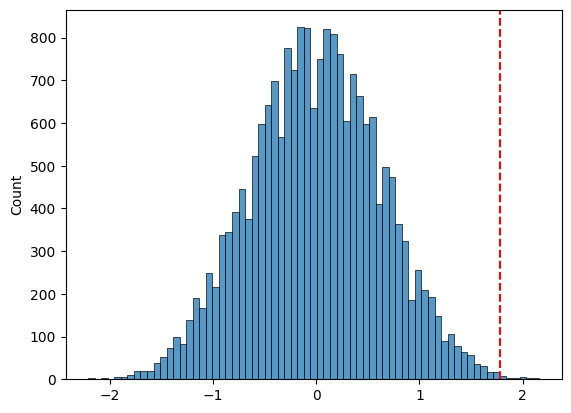

mu_diff: 1.78


In [9]:
sns.histplot(mu_diff_samples)
plt.axvline(mu_diff, 0, 1, color='r', linestyle='--')
plt.show()
print('mu_diff:', round(mu_diff, 2))

È finalmente il momento di calcolare il **[p-value](https://en.wikipedia.org/wiki/P-value)**. Il p-value è un concetto spesso frainteso, quindi spendiamo qualche parola su di esso. Secondo la sua definizione su Wikipedia:

> Il p-value è la **probabilità** di ottenere **risultati del test** almeno **altrettanto estremi** quanto il risultato **effettivamente osservato**, _sotto l'assunzione che l'ipotesi nulla sia corretta_.

Analizziamo questa definizione:

- la prima cosa da notare è che **il p-value è una probabilità**, quindi può assumere solo valori nell'intervallo $[0, 1]$;
- un altro pezzo importante è quello alla fine: _sotto l'assunzione che l'ipotesi nulla sia corretta_; se ricordate, l'ipotesi nulla affermava che la media dei due gruppi era la stessa e abbiamo generato i dati nell'istogramma con questa idea (abbiamo mescolato casualmente i dati dai due gruppi come se non avessero differenze);
- i **risultati del test** sono le differenze tra le medie campionate dei due gruppi che abbiamo calcolato nel ciclo di ricampionamento (200 iterazioni);
- il risultato **effettivamente osservato** è la differenza tra le medie dei gruppi treatment e control che abbiamo calcolato in precedenza e che abbiamo memorizzato nell'oggetto `mu_diff`;
- infine, il p-value è la probabilità di osservare risultati del test **almeno altrettanto estremi** quanto il risultato effettivamente osservato; in termini semplici questo significa che dobbiamo **contare quanti** risultati del test erano >= al `mu_diff` osservato e dividere questo numero per il numero totale di risultati del test calcolati (200 nel nostro caso).

Ecco una spiegazione visiva di cosa è un p-value:

<img src="img/p-value.png" width="600">


Contiamo quante volte i risultati campionati del test erano >= al risultato effettivamente osservato:


In [28]:
sum(mu_diff_samples>mu_diff)

34

Solo un'osservazione dalla nostra procedura di ricampionamento ha avuto un risultato altrettanto estremo quanto quello osservato; dividiamolo per il numero totale di campioni (200) per trovare la probabilità:


In [29]:
p_value = sum(mu_diff_samples>mu_diff)/n
print('p-value: ', p_value)

p-value:  0.0017


Ora, un p-value di 0.005 (può anche essere letto in termini percentuali come 0.5%) è buono o cattivo? Agli statistici non piace l'idea di lasciare al ricercatore o analista la decisione di determinare se un risultato è "troppo insolito" per accadere per caso, quindi **una soglia viene specificata in anticipo**, come in "il valore osservato è più estremo del 5% dei risultati casuali (sotto $H_0$)"; **questa soglia è nota come alpha** o come [livello di significatività](https://en.wikipedia.org/wiki/Statistical_significance).

I livelli alpha tipici sono 10%, 5% e 1% (più basso è il livello alpha, più stringente è il test), con il 5% che è il più ampiamente utilizzato.

> Qualsiasi livello scelto è una decisione arbitraria; non c'è nulla nel processo che garantirà decisioni corrette il x% delle volte. Questo perché la domanda di probabilità a cui si risponde non è "qual è la probabilità che questo sia accaduto per caso?" ma piuttosto "dato un modello casuale (sotto $H_0$), qual è la probabilità di un risultato così estremo?"

Scegliamo un livello alpha del 5% (cioè, $\alpha = 5\%$) e quindi confrontiamo il nostro p-value con questo livello di significatività:

- se $p-value > \alpha$: **accettiamo l'ipotesi nulla** $H_0$ che il risultato osservato non è diverso da un risultato casuale;
- se $p-value <= \alpha$: **rifiutiamo l'ipotesi nulla** $H_0$ e diciamo che il risultato osservato (la differenza nelle medie tra i due gruppi) è **statisticamente significativo**.


In [ ]:
alpha = 0.05
if p_value <= alpha:
    print('p-value <= alpha | il risultato osservato è statisticamente significativo | H0 rifiutata')
else:
    print('p-value > alpha | il risultato osservato non è statisticamente significativo | H0 accettata')

p-value <= alpha | il risultato osservato è statisticamente significativo | H0 rifiutata


Nel nostro esempio, il $p-value=0.005$ è ben al di sotto del livello di significatività $\alpha=0.05$, il che significa che se è vero che il prodotto non ha l'effetto che pubblicizza, allora ottenere la differenza osservata tra i gruppi control e treatment per caso, avviene con una probabilità di solo 0.5%.

Questa è una probabilità molto bassa. Infatti, **al nostro livello di significatività del 5%, rifiutiamo l'ipotesi nulla** e accettiamo l'alternativa: il nuovo prodotto sembra effettivamente funzionare.


---


Per completezza, vediamo anche come usare un t-test per verificare la differenza nelle medie tra i gruppi `treatment` e `control`. Di nuovo, l'ipotesi nulla è che le medie dei due gruppi siano le stesse e scegliamo lo stesso livello di significatività $\alpha=0.05$:


In [31]:
stats.ttest_ind(treatment, control, alternative='greater')

Ttest_indResult(statistic=3.4149113236004656, pvalue=0.0012406913032118703)

In [ ]:
alpha = 0.05
if stats.ttest_ind(treatment, control).pvalue <= alpha:
    print('p-value <= alpha | il risultato osservato è statisticamente significativo | H0 rifiutata')
else:
    print('p-value > alpha | il risultato osservato non è statisticamente significativo | H0 accettata')

p-value <= alpha | il risultato osservato è statisticamente significativo | H0 rifiutata


Come potete vedere, il risultato è lo stesso, sebbene la statistica test e il p-value siano diversi. Di nuovo, la differenza tra questo metodo e il test di permutazione è che:

- qui stiamo assumendo che la distribuzione sottostante segua una distribuzione t di Student e quindi confrontiamo la statistica test (che è stata debitamente calcolata con una [formula](https://en.wikipedia.org/wiki/Student%27s_t-test#Assumptions)) con i valori teorici della distribuzione t;
- in un test di permutazione, non facciamo assunzioni sulla distribuzione dei dati e confrontiamo la statistica test (calcolata come la semplice differenza nelle medie tra i gruppi) con la distribuzione campionata ottenuta tramite il metodo di ricampionamento.


### Test AB


Anche se li abbiamo brevemente menzionati, i test AB sono così frequentemente utilizzati in ambito aziendale, accademico e di ricerca che vale la pena spendere un po' più di tempo a parlarne. Come vedrete, ora abbiamo tutti gli strumenti necessari per affrontarli facilmente: il disegno di un esperimento e il processo di test di ipotesi.


Un **[test AB](https://en.wikipedia.org/wiki/A/B_testing)** è un **esperimento con due gruppi** per stabilire quale tra due farmaci, funzionalità, prodotti o simili sia migliore. Spesso uno dei due gruppi (il controllo) rappresenta lo status-quo. Un'**ipotesi tipica** è che il **treatment sia migliore del control**, rappresentando un [test a una coda](https://en.wikipedia.org/wiki/One-_and_two-tailed_tests).

I test AB sono comuni (ma non limitati a) nel business online e nel marketing, poiché il flusso di lavoro dell'esperimento è facilmente progettabile e i risultati sono facilmente misurabili. Ecco alcuni esempi:

- Testare due pagine carrello per determinare quale produce più conversioni
- Testare due annunci di ricerca a pagamento per determinare quale genera più click
- Testare due farmaci per determinare quale sopprime i sintomi in modo più efficace
- Testare due trattamenti del suolo per determinare quale produce una migliore germinazione dei semi


In un test AB, i **soggetti** sono assegnati casualmente ai gruppi A e B; i soggetti possono essere visitatori web, un gruppo di persone, semi di piante e così via; l'idea chiave è che alcuni soggetti sono esposti al trattamento, mentre altri sono esposti al controllo.

Il **processo di randomizzazione** è fondamentale, poiché in questo modo sapete che qualsiasi differenza tra i gruppi è dovuta a:

- l'effetto dei diversi trattamenti
- l'effetto del caso, cioè l'assegnazione casuale ha portato i soggetti con migliori prestazioni a concentrarsi in A o B

Particolare attenzione deve essere posta nella **statistica test o metrica** usata per confrontare i due gruppi. Una delle metriche più comuni in un contesto aziendale è una **variabile binaria**:

- il visitatore ha cliccato o no
- il cliente ha acquistato o no
- la transazione è risultata in una frode o no


Vediamo un esempio pratico. Sei un data analyst in un e-commerce e il team di prodotto vuole ridisegnare la call-to-action della home page del sito per, si spera, aumentare il click-through rate. Ecco alcuni punti importanti e passi nel disegno e nell'esecuzione dell'esperimento:

1. la proporzione attuale di persone che cliccano sulla call-to-action è circa il 23% dei visitatori;
2. speri di raggiungere almeno un aumento assoluto del 10%, raggiungendo un nuovo click-through rate di circa il 33% con il nuovo redesign;
3. usando un [calcolatore online](https://www.evanmiller.org/ab-testing/sample-size.html#!23;80;5;10;0), scopri che avrai bisogno di una dimensione campionaria di almeno 288 osservazioni per gruppo (controllo e test);
4. imposti il test e dirigi il 50% del traffico del sito alla home page con la nuova call-to-action (gruppo test), mentre il restante 50% continuerà a vedere la CTA usuale (gruppo controllo);
5. lasci che il test venga eseguito per la [quantità di tempo appropriata](https://www.abtasty.com/blog/how-long-run-ab-test/), in base alla tua conoscenza del settore e ciclo di business;
6. infine, raccogli i dati e sei pronto ad analizzarli.


Eseguiremo un **test di permutazione** per valutare se c'è una differenza statisticamente significativa tra i click-through rate dei due gruppi; in particolare, la nostra **ipotesi nulla** è che non ci sia differenza tra il CTR dei due gruppi, che speriamo di rifiutare a favore dell'**alternativa a una coda** che il CTR del gruppo test sia più alto del gruppo controllo:

- $H_0: CTR_{test} = CTR_{control}$
- $H_1: CTR_{test} > CTR_{control}$


Potete vedere il nostro dataset nel DataFrame `ab`, dove abbiamo le colonne `id` e `visit_date` che indicano le singole visite, la variabile `group` ci dice a quale gruppo quella visita è stata assegnata e infine la colonna `clicked` indica se quel visitatore ha cliccato o meno sul pulsante call-to-action.


In [33]:
ab = pd.read_csv("data/ab-test-data.csv")
ab.head()

,id,visit_date,group,clicked
0,1,2018-01-01,control,0
1,2,2018-01-01,control,1
2,3,2018-01-01,control,0
3,4,2018-01-01,control,0
4,5,2018-01-01,test,0


Non ci sono valori mancanti e tutti i dati sono nel formato corretto.


In [34]:
ab.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 588 entries, 0 to 587
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   id          588 non-null    int64 
 1   visit_date  588 non-null    object
 2   group       588 non-null    object
 3   clicked     588 non-null    int64 
dtypes: int64(2), object(2)
memory usage: 18.5+ KB


Calcoliamo alcune **statistiche descrittive**, dove possiamo vedere che:

- abbiamo un totale di 294 osservazioni per gruppo (più del necessario per dimostrare un aumento assoluto del 10%);
- possiamo già vedere che il gruppo test ha ricevuto più click del gruppo controllo;
- notate che il gruppo test ha raggiunto un CTR ben al di sopra della soglia del 33% che avevamo fissato in precedenza.


In [35]:
ab.groupby(['group'], as_index=False).agg({'clicked': ['count', 'sum', np.mean]})

group clicked               
             count  sum      mean
0  control     294   68  0.231293
1     test     294  113  0.384354

In [36]:
mu_test = np.mean(ab[ab.group=='test']['clicked'])
mu_control = np.mean(ab[ab.group=='control']['clicked'])

ab_mu_diff = mu_test - mu_control
print('Differenza CTR osservata:', round(ab_mu_diff, 4))

Differenza CTR osservata: 0.1531


Calcoliamo ora il **test di permutazione** (l'algoritmo sarà lo stesso che abbiamo visto nella sezione precedente) e tracciamo la distribuzione delle statistiche campionate risultanti (nel nostro caso, le differenze tra i CTR campionati):


In [ ]:
n = 2000
np.random.seed(1)
mu_diff_samples = []
for i in range(n):
    # estrai un sotto-campione del 50% dei dati senza reinserimento
    df_sample1 = ab.sample(frac=0.5, replace=False)
    # usa set() per ottenere gli indici delle righe non estratte nel passo precedente
    ix2 = set(ab.index) - set(df_sample1.index)
    # crea il dataframe con l'altro 50% dei dati
    df_sample2 = ab.iloc[list(ix2)]
    # calcola la differenza nelle medie di ciascun campione
    mu_diff_temp = np.mean(df_sample1['clicked']) - np.mean(df_sample2['clicked'])
    # aggiungi la differenza campionata alla lista mu_diff_samples
    mu_diff_samples.append(mu_diff_temp)

In [47]:
sns.histplot(mu_diff_samples)
plt.axvline(ab_mu_diff, 0, 1, color='r', linestyle='--')
plt.show()
print('ab_mu_diff:', round(ab_mu_diff, 2))

Per calcolare il **p-value**, calcoliamo la proporzione del numero di statistiche campionate che erano altrettanto estreme o più estreme della differenza CTR osservata tra i gruppi test e controllo. Come potete vedere dal risultato, ce n'è solo una, quindi il p-value calcolato è 0.0005.


In [48]:
print('Valori più estremi dell\'osservato:', sum([el >= ab_mu_diff for el in mu_diff_samples]))
p_value = sum([el > ab_mu_diff for el in mu_diff_samples])/n
print('p-value:', p_value)

Valori più estremi dell'osservato: 1
p-value: 0.0005


Questo significa che, dato un **livello di significatività alpha** del 5%, possiamo tranquillamente **rifiutare l'ipotesi nulla** e concludere che la differenza nel CTR tra i gruppi test e controllo è **statisticamente significativa**.


---


Per completezza, vediamo anche come raggiungere gli stessi risultati usando uno z-test:


In [ ]:
from statsmodels.stats.weightstats import ztest as ztest
ab_ztest = ztest(x1=ab[ab.group=='test']['clicked'],
                 x2=ab[ab.group=='control']['clicked'],
                 alternative='larger')
ab_ztest

(4.069841267110652, 2.3522590065127384e-05)

In [41]:
print('p-value:', ab_ztest[1])

p-value: 2.3522590065127384e-05


Poiché il p-value è inferiore a $\alpha = 0.05$ (è praticamente molto vicino a zero), possiamo tranquillamente rifiutare l'ipotesi nulla e trarre le stesse conclusioni di sopra.
